<a href="https://colab.research.google.com/github/zeeshan9595/savings-book-forecasting/blob/main/savings_book_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

All libraries loaded successfully
All data loaded — no CSV files needed
  monthly_balances: 18 months
  market_rates:     7 rate snapshots
  monthly_flows:    18 months
  cohort_data:      45 cohort observations

  Total book (Jun 2024): £816,808


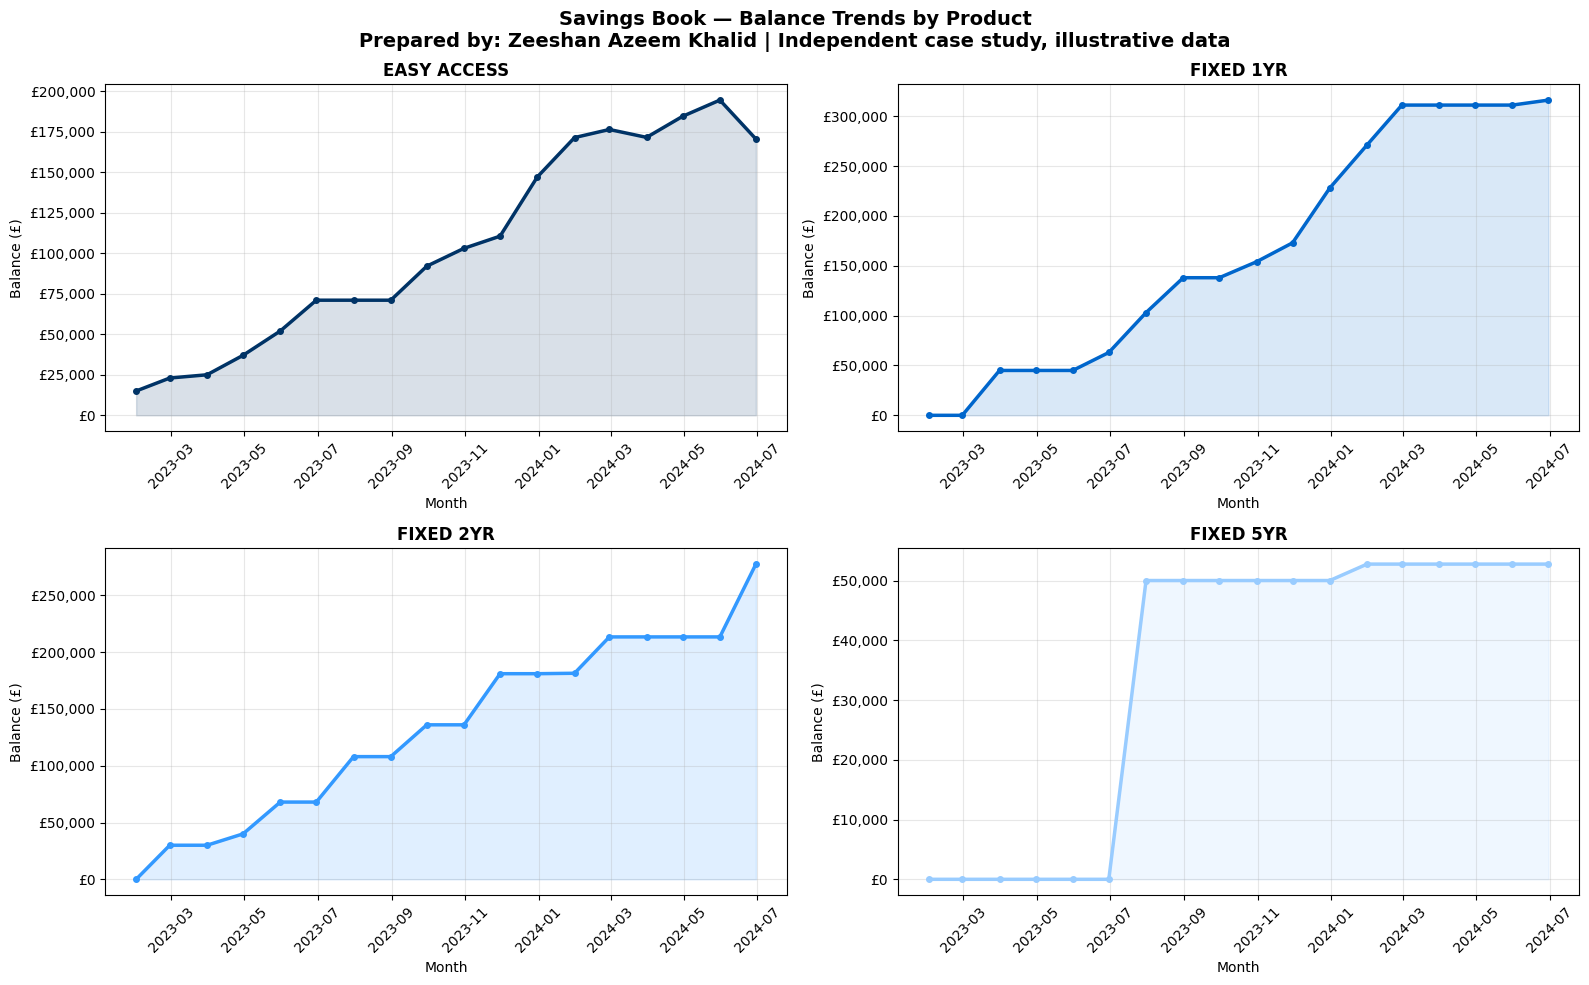

Saved: balance_trends.png
Cohort retention: practice data has no churn events (all 100%), heatmap omitted.

MACRO FORECAST — MODEL COMPARISON ON A 3-MONTH HOLDOUT
                       MAPE (%)  MAE (£)  RMSE (£)    AIC    BIC
Holt-Winters (damped)      10.5  82842.8   85604.7  320.4  324.0
ARIMA(1,1,1)                8.3  65140.6   68156.6  340.3  342.2
Note: AIC/BIC are not comparable across model families (ETS vs differenced ARIMA).

Lower holdout error: ARIMA(1,1,1). With 3 test points, treat this as indicative.

Month        ARIMA mean   Holt-Winters   ARIMA 95% low  ARIMA 95% high
Jul 2024   £    847,700 £      858,159 £       764,689 £       930,711
Aug 2024   £    877,944 £      898,939 £       741,760 £     1,014,129
Sep 2024   £    907,555 £      939,157 £       717,629 £     1,097,482
Oct 2024   £    936,545 £      978,820 £       690,575 £     1,182,516
Nov 2024   £    964,928 £    1,017,935 £       660,300 £     1,269,557
Dec 2024   £    992,716 £    1,056,510 £       626

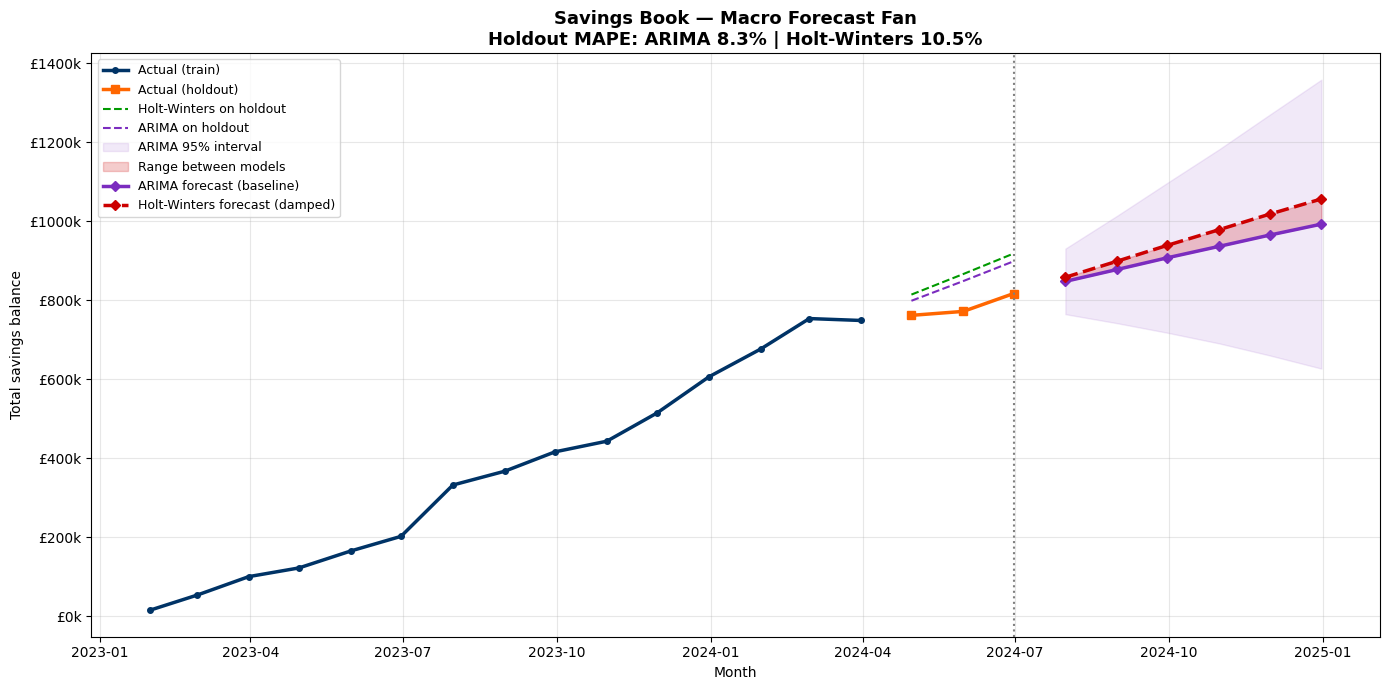

Saved: macro_forecast.png

MICRO FORECAST — EASY ACCESS RATE SENSITIVITY REGRESSION

Easy Access Regression Results:
  Trend (monthly growth):     £    12,399
  Rate differential impact:   £  -116,187 per 1%
  BoE base rate impact:       £   -17,403 per 1%
  In-sample R² (first 15 months):  0.979
  Holdout MAE (last 3 months):   £    36,108
  Note: 18 monthly points and 3 predictors, so treat coefficients as illustrative.

Easy Access 6-Month Scenario Forecast:
Scenario                                        M+3          M+6
----------------------------------------------------------------
Upside   (rate diff +0.00%)            £   256,685 £   293,883
Base     (rate diff -0.30%)            £   291,541 £   328,739
Downside (rate diff -0.60%)            £   330,748 £   367,946

DIAGNOSTICS
ADF Easy access balance, level: statistic -1.21, p-value 0.671
ADF Easy access balance, first difference: statistic -0.79, p-value 0.822
(A p-value above 0.05 means non-stationarity cannot be rejected. 

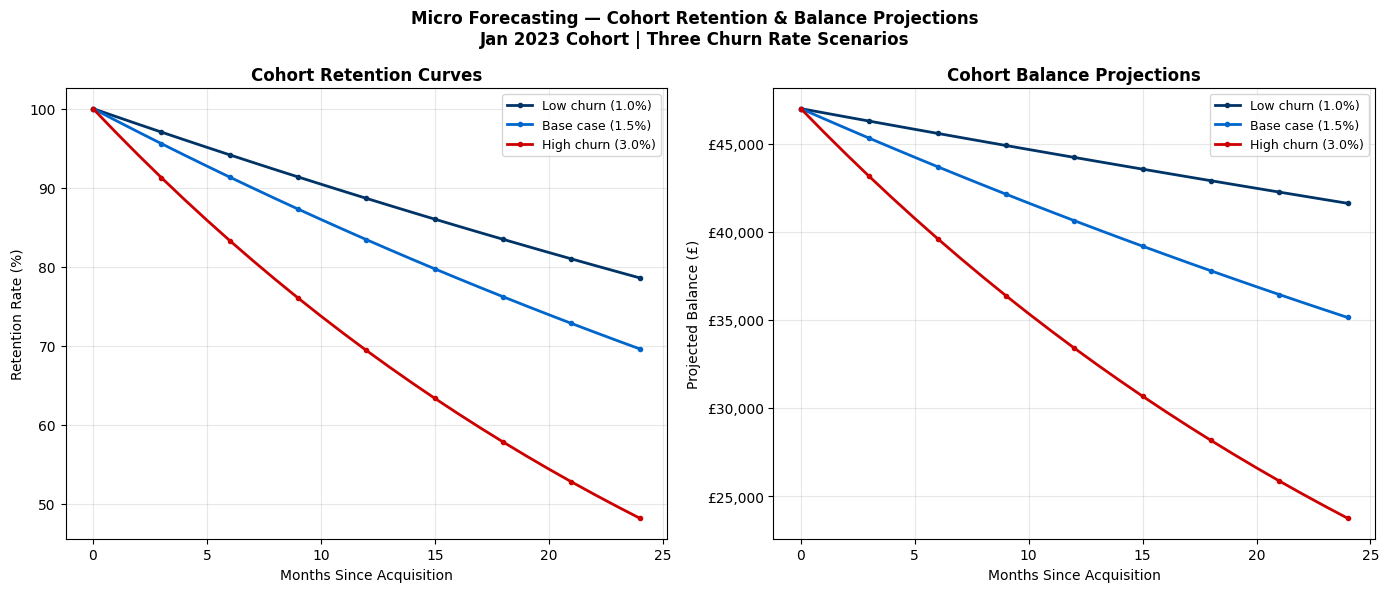

Saved: micro_cohort_forecast.png

RATE-SHOCK GRID — EASY ACCESS
Easy access balance £170,433 at 5.00%
                     Scenario  Our EA rate (%)  Annual interest cost change (£)  Balance effect via spread (£)
              Parallel -200bp             3.00                         -3408.66                       11241.90
              Parallel -100bp             4.00                         -1704.33                        5620.95
               Parallel -50bp             4.50                          -852.16                        2810.47
               Parallel -25bp             4.75                          -426.08                        1405.24
               Parallel +25bp             5.25                           426.08                       -1405.24
               Parallel +50bp             5.50                           852.16                       -2810.47
              Parallel +100bp             6.00                          1704.33                       -5620.95
          

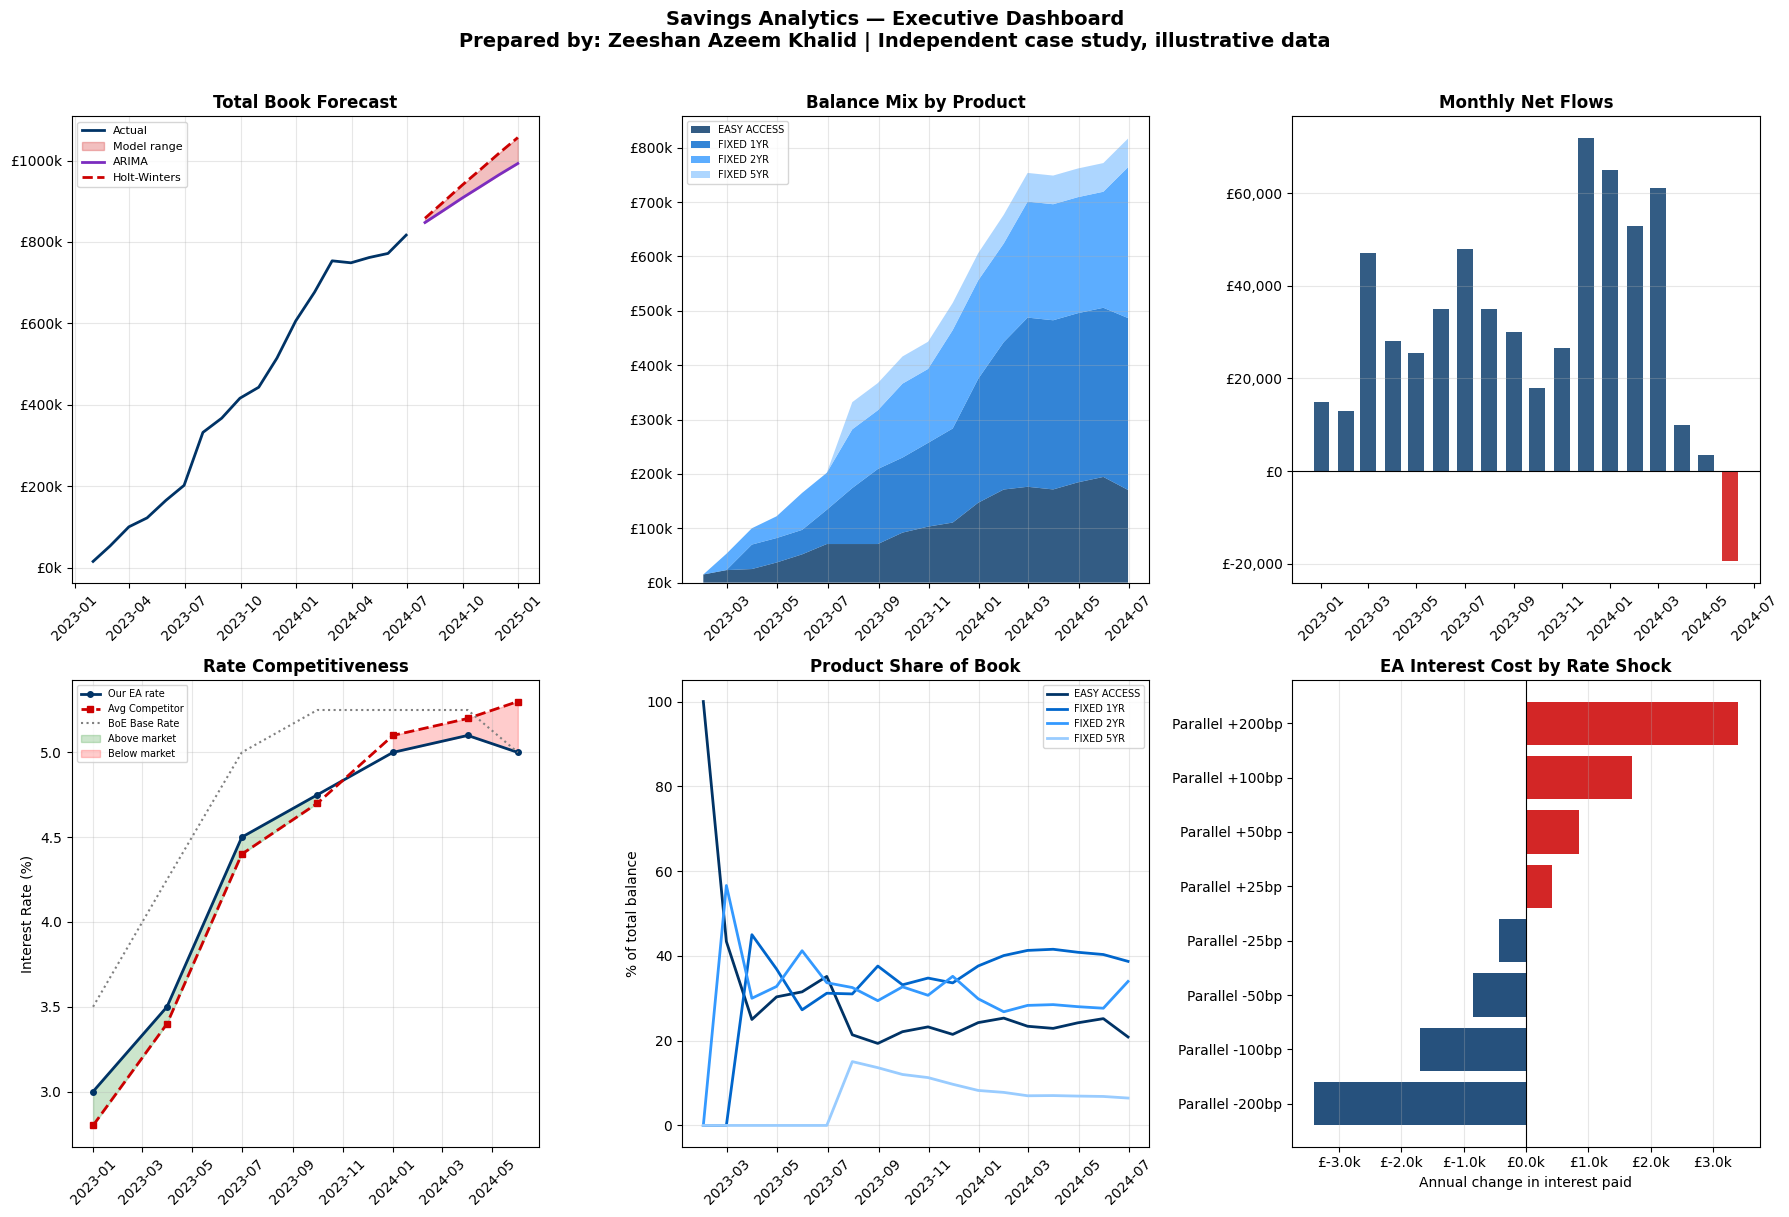

Saved: full_dashboard.png

SUMMARY
 Current savings book (Jun 2024):        £     816,808
 6-month ARIMA baseline:                 £     992,716
 6-month Holt-Winters (damped):          £   1,056,510
 Holdout MAPE: ARIMA 8.3%, Holt-Winters 10.5%
 Deposit beta (hiking cycle): ours 1.00, competitors 1.09
 Spread elasticity (differenced): £65,578 per 1pp (p = 0.25)
 +100bp parallel shock: £1,704 more easy access interest a year

 Caveats: 18 months of illustrative data; forecasts extend the recent trend and
 elasticities are weakly identified. The method is the point, not the numbers.


In [3]:
# ============================================================
# SAVINGS BOOK FORECASTING — INDEPENDENT CASE STUDY
# Google Colab Notebook — FINAL VERSION
# Micro + Macro Forecasting
# Prepared by: Zeeshan Azeem Khalid | Independent case study, illustrative data
# ============================================================

# ============================================================
# CELL 1: INSTALL AND IMPORT
# Run this cell first — uncomment the pip line if needed
# ============================================================

# !pip install statsmodels scikit-learn matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("All libraries loaded successfully")

# ============================================================
# CELL 2: DATA — ILLUSTRATIVE, HARDCODED (mirrors a practice SQL Server database)
# No CSV files needed — everything is self-contained
# ============================================================

# --- monthly_balances: from daily_balances table in SSMS ---
monthly_balances = pd.DataFrame({
    'month': pd.to_datetime([
        '2023-01-31','2023-02-28','2023-03-31','2023-04-30',
        '2023-05-31','2023-06-30','2023-07-31','2023-08-31',
        '2023-09-30','2023-10-31','2023-11-30','2023-12-31',
        '2024-01-31','2024-02-29','2024-03-31','2024-04-30',
        '2024-05-31','2024-06-30'
    ]),
    'EASY_ACCESS': [
        15000,  23000,  25000,  37000,
        52000,  71000,  71000,  71000,
        92000, 103000, 110500, 147000,
       171294, 176294, 171422, 184422,
       194422, 170433
    ],
    'FIXED_1YR': [
            0,      0,  45000,  45000,
        45000,  63000, 103000, 138000,
       138000, 154000, 173000, 228000,
       271141, 311141, 311141, 311141,
       311141, 316141
    ],
    'FIXED_2YR': [
            0,  30000,  30000,  40000,
        68000,  68000, 108000, 108000,
       136000, 136000, 181000, 181000,
       181390, 213390, 213390, 213390,
       213390, 277484
    ],
    'FIXED_5YR': [
            0,      0,      0,      0,
            0,      0,  50000,  50000,
        50000,  50000,  50000,  50000,
        52750,  52750,  52750,  52750,
        52750,  52750
    ]
})

# --- market_rates: from market_rates table in SSMS ---
market_rates = pd.DataFrame({
    'rate_date': pd.to_datetime([
        '2023-01-01','2023-04-01','2023-07-01',
        '2023-10-01','2024-01-01','2024-04-01','2024-06-01'
    ]),
    'EASY_ACCESS_ours':     [3.000, 3.500, 4.500, 4.750, 5.000, 5.100, 5.000],
    'EASY_ACCESS_competitor': [2.800, 3.400, 4.400, 4.700, 5.100, 5.200, 5.300],
    'FIXED_1YR_ours':       [4.200, 4.600, 5.100, 5.000, 5.150, 5.200, 5.000],
    'FIXED_1YR_competitor':   [4.000, 4.500, 5.000, 5.100, 5.200, 5.300, 5.350],
    'boe_base_rate':          [3.500, 4.250, 5.000, 5.250, 5.250, 5.250, 5.000]
})

# --- monthly_flows: from transactions table in SSMS ---
monthly_flows = pd.DataFrame({
    'month': pd.to_datetime([
        '2023-01-01','2023-02-01','2023-03-01','2023-04-01',
        '2023-05-01','2023-06-01','2023-07-01','2023-08-01',
        '2023-09-01','2023-10-01','2023-11-01','2023-12-01',
        '2024-01-01','2024-02-01','2024-03-01','2024-04-01',
        '2024-05-01','2024-06-01'
    ]),
    'gross_inflows': [
        15000, 13000, 47000, 28000,
        25500, 35000, 50000, 35000,
        30000, 18000, 26500, 72000,
        65000, 53000, 68000, 10000,
         3500,  2000
    ],
    'gross_outflows': [
            0,     0,     0,     0,
            0,     0,  2000,     0,
            0,     0,     0,     0,
            0,     0,  7000,     0,
            0, 21500
    ],
    'new_customers': [
        1,2,2,2,2,1,2,1,1,2,2,2,2,2,2,2,0,0
    ]
})

# --- cohort_retention: result of SSMS Query 3 ---
cohort_data = pd.DataFrame({
    'cohort_month': pd.to_datetime([
        '2023-01-01','2023-01-01','2023-01-01','2023-01-01',
        '2023-02-01','2023-02-01','2023-02-01','2023-02-01',
        '2023-03-01','2023-03-01','2023-03-01','2023-03-01',
        '2023-04-01','2023-04-01','2023-04-01','2023-04-01',
        '2023-05-01','2023-05-01','2023-05-01',
        '2023-06-01','2023-06-01','2023-06-01',
        '2023-07-01','2023-07-01','2023-07-01','2023-07-01',
        '2023-08-01','2023-08-01','2023-08-01',
        '2023-09-01','2023-09-01',
        '2023-10-01','2023-10-01','2023-10-01',
        '2023-11-01','2023-11-01','2023-11-01',
        '2023-12-01','2023-12-01',
        '2024-01-01','2024-01-01',
        '2024-02-01','2024-02-01',
        '2024-03-01','2024-03-01'
    ]),
    'months_since_acq': [
         0, 3, 6,17,
         0, 3, 7,16,
         0, 3, 6,15,
         0, 2, 5,14,
         0, 4,13,
         0, 6,12,
         0, 3, 5,11,
         0, 4,10,
         0, 9,
         0, 2, 8,
         0, 1, 7,
         0, 6,
         0, 5,
         0, 4,
         0, 3
    ],
    'retention_rate': [100]*45
})

monthly_balances['total_balance'] = (
    monthly_balances['EASY_ACCESS'] +
    monthly_balances['FIXED_1YR'] +
    monthly_balances['FIXED_2YR'] +
    monthly_balances['FIXED_5YR']
)
monthly_flows['net_flows'] = (
    monthly_flows['gross_inflows'] -
    monthly_flows['gross_outflows']
)

print("All data loaded — no CSV files needed")
print(f"  monthly_balances: {len(monthly_balances)} months")
print(f"  market_rates:     {len(market_rates)} rate snapshots")
print(f"  monthly_flows:    {len(monthly_flows)} months")
print(f"  cohort_data:      {len(cohort_data)} cohort observations")
print(f"\n  Total book (Jun 2024): "
      f"£{monthly_balances['total_balance'].iloc[-1]:,.0f}")

# ============================================================
# CELL 3: BALANCE TREND CHARTS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle(
    'Savings Book — Balance Trends by Product\n'
    'Prepared by: Zeeshan Azeem Khalid | Independent case study, illustrative data',
    fontsize=14, fontweight='bold'
)

products = ['EASY_ACCESS','FIXED_1YR','FIXED_2YR','FIXED_5YR']
colours  = ['#003366','#0066CC','#3399FF','#99CCFF']

for i, (product, colour) in enumerate(zip(products, colours)):
    ax = axes[i//2][i%2]
    ax.plot(
        monthly_balances['month'],
        monthly_balances[product],
        color=colour, linewidth=2.5,
        marker='o', markersize=4
    )
    ax.fill_between(
        monthly_balances['month'],
        monthly_balances[product],
        alpha=0.15, color=colour
    )
    ax.set_title(product.replace('_',' '), fontweight='bold')
    ax.set_xlabel('Month')
    ax.set_ylabel('Balance (£)')
    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f'£{x:,.0f}'))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('balance_trends.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: balance_trends.png")

# ============================================================
# CELL 4: COHORT RETENTION (NOT SHOWN)
# The practice data contains no churn events: every cohort's retention is 100%.
# A heatmap would be all 100s and say nothing, so it is omitted. Cohort projections
# in Cell 8 use assumed churn scenarios instead.
# ============================================================
print("Cohort retention: practice data has no churn events (all 100%), heatmap omitted.")

# ============================================================
# CELL 5: MACRO FORECASTING — HOLT-WINTERS vs ARIMA(1,1,1)
# Dates: balances are month-end, so the series is indexed with freq='ME'.
# The backtest window is the last 3 actual months, not generated dates.
# ============================================================
print("\n" + "="*60)
print("MACRO FORECAST — MODEL COMPARISON ON A 3-MONTH HOLDOUT")
print("="*60)

balance_series = monthly_balances.set_index('month')['total_balance'].asfreq('ME')
train = balance_series.iloc[:-3]
test = balance_series.iloc[-3:]
test_dates = test.index
forecast_periods = 6
forecast_dates = pd.date_range(balance_series.index[-1] + pd.offsets.MonthEnd(1),
                               periods=forecast_periods, freq='ME')

def fc_metrics(actual, pred):
    a, p = np.asarray(actual, float), np.asarray(pred, float)
    return {'MAPE (%)': np.mean(np.abs((a - p) / a)) * 100,
            'MAE (£)': mean_absolute_error(a, p),
            'RMSE (£)': np.sqrt(mean_squared_error(a, p))}

model_hw = ExponentialSmoothing(train, trend='add', seasonal=None, damped_trend=True).fit(optimized=True)
model_arima = ARIMA(train, order=(1, 1, 1)).fit()
hw_test = model_hw.forecast(len(test))
ar_test = model_arima.forecast(len(test))

backtest = pd.DataFrame({'Holt-Winters (damped)': fc_metrics(test, hw_test),
                         'ARIMA(1,1,1)': fc_metrics(test, ar_test)}).T
backtest['AIC'] = [model_hw.aic, model_arima.aic]
backtest['BIC'] = [model_hw.bic, model_arima.bic]
print(backtest.round(1).to_string())
print("Note: AIC/BIC are not comparable across model families (ETS vs differenced ARIMA).")
mape, arima_mape = backtest['MAPE (%)'].iloc[0], backtest['MAPE (%)'].iloc[1]
winner = 'ARIMA(1,1,1)' if arima_mape < mape else 'Holt-Winters'
print(f"\nLower holdout error: {winner}. With 3 test points, treat this as indicative.")

# Forward forecasts: refit both models on all 18 months
hw_full = ExponentialSmoothing(balance_series, trend='add', seasonal=None, damped_trend=True).fit(optimized=True)
ar_full = ARIMA(balance_series, order=(1, 1, 1)).fit()
fc_vals = pd.Series(np.asarray(hw_full.forecast(forecast_periods)), index=forecast_dates)
ar_fc = ar_full.get_forecast(forecast_periods)
arima_path = pd.Series(np.asarray(ar_fc.predicted_mean), index=forecast_dates)
arima_ci = pd.DataFrame(np.asarray(ar_fc.conf_int(alpha=0.05)), index=forecast_dates, columns=['lower', 'upper'])
band_lo = np.minimum(fc_vals, arima_path)
band_hi = np.maximum(fc_vals, arima_path)

print(f"\n{'Month':<10} {'ARIMA mean':>12} {'Holt-Winters':>14} {'ARIMA 95% low':>15} {'ARIMA 95% high':>15}")
for d in forecast_dates:
    print(f"{d.strftime('%b %Y'):<10} £{arima_path[d]:>11,.0f} £{fc_vals[d]:>13,.0f} "
          f"£{arima_ci.loc[d,'lower']:>14,.0f} £{arima_ci.loc[d,'upper']:>14,.0f}")

fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(train.index, train.values, color='#003366', lw=2.5, marker='o', ms=4, label='Actual (train)')
ax.plot(test.index, test.values, color='#FF6600', lw=2.5, marker='s', ms=6, label='Actual (holdout)')
ax.plot(test.index, hw_test.values, color='#009900', lw=1.5, ls='--', label='Holt-Winters on holdout')
ax.plot(test.index, ar_test.values, color='#7B2CBF', lw=1.5, ls='--', label='ARIMA on holdout')
ax.fill_between(forecast_dates, arima_ci['lower'], arima_ci['upper'], color='#7B2CBF', alpha=0.10, label='ARIMA 95% interval')
ax.fill_between(forecast_dates, band_lo, band_hi, color='#CC0000', alpha=0.20, label='Range between models')
ax.plot(forecast_dates, arima_path, color='#7B2CBF', lw=2.5, marker='D', ms=5, label='ARIMA forecast (baseline)')
ax.plot(forecast_dates, fc_vals, color='#CC0000', lw=2.5, ls='--', marker='D', ms=5, label='Holt-Winters forecast (damped)')
ax.axvline(balance_series.index[-1], color='grey', ls=':', lw=1.5)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'£{x/1000:.0f}k'))
ax.set_title(f'Savings Book — Macro Forecast Fan\nHoldout MAPE: ARIMA {arima_mape:.1f}% | Holt-Winters {mape:.1f}%',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Month'); ax.set_ylabel('Total savings balance')
ax.legend(loc='upper left', fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig('macro_forecast.png', dpi=150, bbox_inches='tight'); plt.show()
print("Saved: macro_forecast.png")

# ============================================================
# CELL 7: MICRO FORECASTING — PRODUCT LEVEL REGRESSION
# ============================================================

print("\n" + "="*60)
print("MICRO FORECAST — EASY ACCESS RATE SENSITIVITY REGRESSION")
print("="*60)

# Forward-fill market rates to monthly
mr = (
    market_rates
    .set_index('rate_date')
    .resample('MS').ffill()
    .reset_index()
)
mr['ea_rate_diff'] = (
    mr['EASY_ACCESS_ours'] - mr['EASY_ACCESS_competitor']
)

# Merge balance + rates
bal = monthly_balances.copy()
bal['month'] = bal['month'].dt.to_period('M').dt.to_timestamp()
merged = pd.merge_asof(
    bal.sort_values('month'),
    mr[['rate_date','ea_rate_diff','boe_base_rate']],
    left_on='month', right_on='rate_date',
    direction='backward'
).dropna()

merged['trend'] = range(len(merged))

X = merged[['trend','ea_rate_diff','boe_base_rate']].values
y = merged['EASY_ACCESS'].values

reg = LinearRegression().fit(X[:-3], y[:-3])

print(f"\nEasy Access Regression Results:")
print(f"  Trend (monthly growth):     £{reg.coef_[0]:>10,.0f}")
print(f"  Rate differential impact:   £{reg.coef_[1]:>10,.0f} per 1%")
print(f"  BoE base rate impact:       £{reg.coef_[2]:>10,.0f} per 1%")
print(f"  In-sample R² (first 15 months): {reg.score(X[:-3], y[:-3]):>6.3f}")
holdout_mae = mean_absolute_error(y[-3:], reg.predict(X[-3:]))
print(f"  Holdout MAE (last 3 months):   £{holdout_mae:>10,.0f}")
print("  Note: 18 monthly points and 3 predictors, so treat coefficients as illustrative.")

base_balance = y[-1]
last_trend   = len(merged) - 1

scenarios = {
    'Upside   (rate diff +0.00%)': ( 0.00, 4.75),
    'Base     (rate diff -0.30%)': (-0.30, 4.75),
    'Downside (rate diff -0.60%)': (-0.60, 4.50),
}

print(f"\nEasy Access 6-Month Scenario Forecast:")
print(f"{'Scenario':<38} {'M+3':>12} {'M+6':>12}")
print("-" * 64)
for name, (rd, boe) in scenarios.items():
    vals = [
        reg.predict([[last_trend + m, rd, boe]])[0]
        for m in range(1, 7)
    ]
    print(f"{name:<38} £{vals[2]:>10,.0f} £{vals[5]:>10,.0f}")

# ============================================================
# CELL 7B: ECONOMETRIC DIAGNOSTICS AND A DIFFERENCED ELASTICITY MODEL
# The levels regression in Cell 7 is shown for comparison. Balances trend
# upward and the base rate rose over the same months, so a levels regression
# can find relationships that are really two trends moving together.
# ============================================================
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

print("\n" + "="*60)
print("DIAGNOSTICS")
print("="*60)
ea = merged.set_index('month')['EASY_ACCESS']
for name, series in [('Easy access balance, level', ea), ('Easy access balance, first difference', ea.diff().dropna())]:
    stat, p = adfuller(series, maxlag=2, autolag=None)[:2]
    print(f"ADF {name}: statistic {stat:.2f}, p-value {p:.3f}")
print("(A p-value above 0.05 means non-stationarity cannot be rejected. With ~17 points the test has low power.)")

Xv = sm.add_constant(pd.DataFrame(X, columns=['trend', 'rate_spread', 'boe_rate']))
vif = {col: variance_inflation_factor(Xv.values, i) for i, col in enumerate(Xv.columns) if col != 'const'}
print("VIF, levels model:", {k: round(v, 1) for k, v in vif.items()}, "(above 10 = severe collinearity)")
print(f"Levels model rate-spread coefficient: £{reg.coef_[1]:,.0f} per 1pp")

d = merged[['EASY_ACCESS', 'ea_rate_diff', 'boe_base_rate']].diff().dropna()
d.columns = ['d_balance', 'd_spread', 'd_boe']
d['d_spread_lag1'] = d['d_spread'].shift(1)
diff_model = sm.OLS(d['d_balance'], sm.add_constant(d[['d_spread', 'd_boe']])).fit()
dl = d.dropna()
lag_model = sm.OLS(dl['d_balance'], sm.add_constant(dl[['d_spread', 'd_spread_lag1', 'd_boe']])).fit()
print("\nFirst-difference model: change in balance ~ change in spread + change in base rate")
print(diff_model.summary().tables[1])
print(f"n = {int(diff_model.nobs)}, R² = {diff_model.rsquared:.3f}")
print("\nWith a one-month lag on the spread:")
print(lag_model.summary().tables[1])
print(f"n = {int(lag_model.nobs)}, R² = {lag_model.rsquared:.3f}")
beta_spread = diff_model.params['d_spread']
p_spread = diff_model.pvalues['d_spread']
print(f"\nSpread elasticity (differenced): £{beta_spread:,.0f} per 1pp, p = {p_spread:.2f}. "
      "The spread changes in only a few months, so this is weakly identified.")

# Deposit beta: how much of a base-rate move is passed on to the easy access rate
r = market_rates.set_index('rate_date')
hike = r.loc[:'2023-10-01']
boe_move = hike['boe_base_rate'].iloc[-1] - hike['boe_base_rate'].iloc[0]
beta_ours = (hike['EASY_ACCESS_ours'].iloc[-1] - hike['EASY_ACCESS_ours'].iloc[0]) / boe_move
beta_comp = (hike['EASY_ACCESS_competitor'].iloc[-1] - hike['EASY_ACCESS_competitor'].iloc[0]) / boe_move
print(f"\nDeposit beta, hiking cycle Jan-Oct 2023: ours {beta_ours:.2f}, competitor average {beta_comp:.2f}")
print("Beta = change in easy access rate / change in Bank of England base rate.")

# ============================================================
# CELL 8: MICRO FORECASTING — COHORT BALANCE PROJECTION
# ============================================================

print("\n" + "="*60)
print("MICRO FORECAST — COHORT BALANCE PROJECTION")
print("="*60)

def project_cohort(initial_balance, months,
                   churn_rate, balance_growth):
    rows = []
    for m in range(months + 1):
        retention  = (1 - churn_rate) ** m
        bal_per_c  = initial_balance * (1 + balance_growth) ** m
        proj_bal   = bal_per_c * retention
        rows.append({
            'month': m,
            'retention_pct': retention * 100,
            'projected_balance': proj_bal
        })
    return pd.DataFrame(rows)

churn_scenarios = {
    'Low churn (1.0%)':  (0.010, 0.005),
    'Base case (1.5%)':  (0.015, 0.003),
    'High churn (3.0%)': (0.030, 0.002),
}

print("\nBase case cohort projection (Jan 2023, £47,000):")
print(f"{'Month':<8} {'Retention':>11} {'Balance':>14}")
print("-" * 35)
base_proj = project_cohort(47000, 24, 0.015, 0.003)
for _, row in base_proj.iloc[::3].iterrows():
    print(f"  {int(row['month']):<6} "
          f"{row['retention_pct']:>9.1f}%  "
          f"£{row['projected_balance']:>11,.0f}")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colours_sc = ['#003366','#0066CC','#CC0000']

for ax, metric, ylabel, title in zip(
    axes,
    ['retention_pct', 'projected_balance'],
    ['Retention Rate (%)', 'Projected Balance (£)'],
    ['Cohort Retention Curves', 'Cohort Balance Projections']
):
    for (name, (cr, bg)), col in zip(
            churn_scenarios.items(), colours_sc):
        df = project_cohort(47000, 24, cr, bg)
        ax.plot(df['month'], df[metric],
                label=name, color=col,
                linewidth=2, marker='o',
                markersize=3, markevery=3)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Months Since Acquisition')
    ax.set_ylabel(ylabel)
    if metric == 'projected_balance':
        ax.yaxis.set_major_formatter(
            mticker.FuncFormatter(
                lambda x, _: f'£{x:,.0f}'))
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

fig.suptitle(
    'Micro Forecasting — Cohort Retention & Balance Projections\n'
    'Jan 2023 Cohort | Three Churn Rate Scenarios',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig('micro_cohort_forecast.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: micro_cohort_forecast.png")

# ============================================================
# CELL 9: RATE-SHOCK GRID
# Parallel shocks pass through to our rate via the hiking-cycle deposit beta.
# Spread effects use the differenced elasticity and are illustrative only.
# ============================================================
print("\n" + "="*60)
print("RATE-SHOCK GRID — EASY ACCESS")
print("="*60)
ea_bal = monthly_balances['EASY_ACCESS'].iloc[-1]
ea_rate_now = market_rates['EASY_ACCESS_ours'].iloc[-1]
shock_rows = []
for bp in [-200, -100, -50, -25, 25, 50, 100, 200]:
    sh = bp / 100
    d_ours, d_comp = beta_ours * sh, beta_comp * sh
    shock_rows.append({'Scenario': f'Parallel {bp:+d}bp', 'Our EA rate (%)': ea_rate_now + d_ours,
                       'Annual interest cost change (£)': ea_bal * d_ours / 100,
                       'Balance effect via spread (£)': beta_spread * (d_ours - d_comp)})
for bp in [25, 50]:
    shock_rows.append({'Scenario': f'Competitors +{bp}bp, base fixed', 'Our EA rate (%)': ea_rate_now,
                       'Annual interest cost change (£)': 0.0,
                       'Balance effect via spread (£)': beta_spread * (-bp / 100)})
shock = pd.DataFrame(shock_rows)
print(f"Easy access balance £{ea_bal:,.0f} at {ea_rate_now:.2f}%")
print(shock.round(2).to_string(index=False))
print("Balance effects use a weakly identified elasticity; read them as direction and rough size only.")

# ============================================================
# CELL 10: FULL EXECUTIVE DASHBOARD
# ============================================================

fig = plt.figure(figsize=(18, 12))
fig.suptitle(
    'Savings Analytics — Executive Dashboard\n'
    'Prepared by: Zeeshan Azeem Khalid | Independent case study, illustrative data',
    fontsize=14, fontweight='bold', y=1.01
)

# Panel 1 — Total book with both forecasts
ax1 = fig.add_subplot(2, 3, 1)
ax1.plot(balance_series.index, balance_series.values, color='#003366', linewidth=2, label='Actual')
ax1.fill_between(forecast_dates, band_lo, band_hi, alpha=0.25, color='#CC0000', label='Model range')
ax1.plot(forecast_dates, arima_path, color='#7B2CBF', linewidth=2, label='ARIMA')
ax1.plot(forecast_dates, fc_vals, color='#CC0000', linewidth=2, linestyle='--', label='Holt-Winters')
ax1.set_title('Total Book Forecast', fontweight='bold')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'£{x/1000:.0f}k'))
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)
ax1.tick_params(axis='x', rotation=45)

# Panel 2 — Product mix stacked
ax2 = fig.add_subplot(2, 3, 2)
ax2.stackplot(
    monthly_balances['month'],
    [monthly_balances[p] for p in products],
    labels=[p.replace('_',' ') for p in products],
    colors=colours, alpha=0.8
)
ax2.set_title('Balance Mix by Product', fontweight='bold')
ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'£{x/1000:.0f}k'))
ax2.legend(fontsize=7, loc='upper left')
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis='x', rotation=45)

# Panel 3 — Net flows bar
ax3 = fig.add_subplot(2, 3, 3)
bar_colours = [
    '#003366' if v >= 0 else '#CC0000'
    for v in monthly_flows['net_flows']
]
ax3.bar(monthly_flows['month'],
        monthly_flows['net_flows'],
        color=bar_colours, alpha=0.8, width=20)
ax3.axhline(y=0, color='black', linewidth=0.8)
ax3.set_title('Monthly Net Flows', fontweight='bold')
ax3.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'£{x:,.0f}'))
ax3.tick_params(axis='x', rotation=45)
ax3.grid(True, alpha=0.3, axis='y')

# Panel 4 — Rate competitiveness
ax4 = fig.add_subplot(2, 3, 4)
ax4.plot(market_rates['rate_date'],
         market_rates['EASY_ACCESS_ours'],
         color='#003366', linewidth=2,
         label='Our EA rate', marker='o', markersize=4)
ax4.plot(market_rates['rate_date'],
         market_rates['EASY_ACCESS_competitor'],
         color='#CC0000', linewidth=2,
         linestyle='--', label='Avg Competitor',
         marker='s', markersize=4)
ax4.plot(market_rates['rate_date'],
         market_rates['boe_base_rate'],
         color='grey', linewidth=1.5,
         linestyle=':', label='BoE Base Rate')
ax4.fill_between(
    market_rates['rate_date'],
    market_rates['EASY_ACCESS_ours'],
    market_rates['EASY_ACCESS_competitor'],
    where=(market_rates['EASY_ACCESS_ours'] >=
           market_rates['EASY_ACCESS_competitor']),
    alpha=0.2, color='green', label='Above market'
)
ax4.fill_between(
    market_rates['rate_date'],
    market_rates['EASY_ACCESS_ours'],
    market_rates['EASY_ACCESS_competitor'],
    where=(market_rates['EASY_ACCESS_ours'] <
           market_rates['EASY_ACCESS_competitor']),
    alpha=0.2, color='red', label='Below market'
)
ax4.set_title('Rate Competitiveness', fontweight='bold')
ax4.set_ylabel('Interest Rate (%)')
ax4.legend(fontsize=7)
ax4.grid(True, alpha=0.3)
ax4.tick_params(axis='x', rotation=45)

# Panel 5 — Product share of book (%)
ax5 = fig.add_subplot(2, 3, 5)
share = monthly_balances[products].div(monthly_balances['total_balance'], axis=0) * 100
for product, colour in zip(products, colours):
    ax5.plot(monthly_balances['month'], share[product], color=colour, linewidth=2, label=product.replace('_',' '))
ax5.set_title('Product Share of Book', fontweight='bold')
ax5.set_ylabel('% of total balance')
ax5.legend(fontsize=7)
ax5.grid(True, alpha=0.3)
ax5.tick_params(axis='x', rotation=45)

# Panel 6 — Interest cost under parallel shocks
ax6 = fig.add_subplot(2, 3, 6)
par = shock[shock['Scenario'].str.startswith('Parallel')]
ax6.barh(par['Scenario'], par['Annual interest cost change (£)'],
         color=['#003366' if v < 0 else '#CC0000' for v in par['Annual interest cost change (£)']], alpha=0.85)
ax6.axvline(0, color='black', linewidth=0.8)
ax6.set_title('EA Interest Cost by Rate Shock', fontweight='bold')
ax6.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'£{x/1000:.1f}k'))
ax6.set_xlabel('Annual change in interest paid')
ax6.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('full_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: full_dashboard.png")

# ============================================================
# CELL 11: SUMMARY
# ============================================================
current = balance_series.iloc[-1]
print("\n" + "="*60)
print("SUMMARY")
print("="*60)
print(f" Current savings book (Jun 2024):        £{current:>12,.0f}")
print(f" 6-month ARIMA baseline:                 £{arima_path.iloc[-1]:>12,.0f}")
print(f" 6-month Holt-Winters (damped):          £{fc_vals.iloc[-1]:>12,.0f}")
print(f" Holdout MAPE: ARIMA {arima_mape:.1f}%, Holt-Winters {mape:.1f}%")
print(f" Deposit beta (hiking cycle): ours {beta_ours:.2f}, competitors {beta_comp:.2f}")
print(f" Spread elasticity (differenced): £{beta_spread:,.0f} per 1pp (p = {p_spread:.2f})")
print(f" +100bp parallel shock: £{ea_bal*beta_ours/100:,.0f} more easy access interest a year")
print("\n Caveats: 18 months of illustrative data; forecasts extend the recent trend and")
print(" elasticities are weakly identified. The method is the point, not the numbers.")
print("="*60)
